In [1]:
import numpy as np
import tensorflow as tf
from keras.datasets.cifar10 import load_data
from keras.optimizers import Adam
from keras.models import Model
from keras.layers import Input
from keras.layers import Dense
from keras.layers import Reshape
from keras.layers import Flatten
from keras.layers import Conv2D
from keras.layers import Conv2DTranspose
from keras.layers import LeakyReLU
from keras.layers import Dropout
from keras.layers import Embedding
from keras.layers import Concatenate
from keras.layers import BatchNormalization
from keras.utils import plot_model

from matplotlib import pyplot as plt

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9607843137254902..0.9921568627450981].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.8431372549019608..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9686274509803922..0.8352941176470589].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9921568627450981].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9764705882352941].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] fo

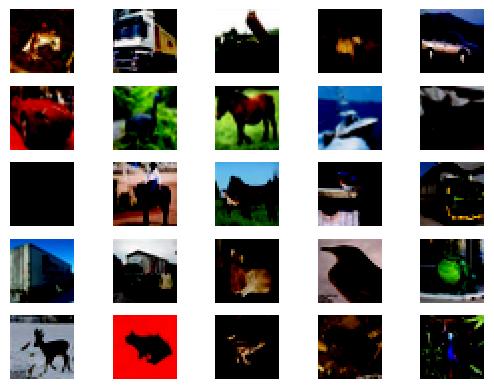

In [2]:
(x_train, y_train), (x_test, y_test) = load_data()
x_train = (x_train - 127.5) / 127.5

# plot 25 images
for i in range(25):
	plt.subplot(5, 5, 1 + i)
	plt.axis('off')
	plt.imshow(x_train[i])
plt.show()

In [3]:
def define_discriminator(in_shape=(32,32,3), n_classes=10):
	# Label input
	input_1=Input(shape=(1,))
	x1=Embedding(n_classes,50)(input_1)
	x1=Dense(32*32)(x1)
	x1=Reshape((32,32,1))(x1)

	# Image input
	input_2=Input(shape=in_shape)
	x=Concatenate()([input_2,x1])

	x=Conv2D(128,(3,3),strides=(2,2),padding='same',)(x)
	x=LeakyReLU(alpha=.2)(x)
	x=Conv2D(128,(3,3),strides=(2,2),padding='same')(x)
	x=LeakyReLU(alpha=.2)(x)

	flatten=Flatten()(x)
	x=Dropout(.4)(flatten)

	output=Dense(1,activation='sigmoid')(x)
	model=Model([input_2,input_1],output)
	opt = Adam(learning_rate=0.0002, beta_1=0.5)

	model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
	plot_model(model, to_file='./discriminator.png', show_shapes=True, show_layer_names=True)
	model.summary()

	return model

In [4]:
def define_generator(n_classes=10, latent_dim=100):
    # Label input
    input_1=Input(shape=(1,))
    x1=Embedding(n_classes,50)(input_1)
    x1=Dense(8*8*1)(x1)
    x1=Reshape((8,8,1))(x1)

    # Image noise input
    input_2=Input(shape=(latent_dim,))
    x2=Dense(8*8*128)(input_2)
    x2=LeakyReLU(alpha=.2)(x2)
    x2=Reshape((8,8,128))(x2)

    x=Concatenate()([x2,x1])

    x=Conv2DTranspose(128, (4,4), strides=(2,2), padding='same')(x)
    x=LeakyReLU(alpha=.2)(x)
    x=Conv2DTranspose(128,(4,4),strides=(2,2),padding='same')(x)
    x=LeakyReLU(alpha=.2)(x)
    
    # Output image
    output= Conv2D(3, (8,8), activation='tanh', padding='same')(x)
    model=Model( [input_2,input_1],output)

    plot_model(model, to_file='./generator.png', show_shapes=True, show_layer_names=True)
    model.summary()

    return model

In [5]:
def define_gan(g_model, d_model):
	d_model.trainable=False
	vec, label = g_model.input
	fake_image = g_model.output
	output = d_model([fake_image,label])

	model=Model([vec,label],output)
	opt = Adam(learning_rate=0.0002, beta_1=0.5)

	model.compile(loss='binary_crossentropy', optimizer=opt)

	return model

In [6]:

def get_latent(n_sample, latent_dim=100, n_classes=10):
    vec=np.random.randn(n_sample,latent_dim)
    label=np.random.randint(0,n_classes,n_sample)
    return  vec,label

# select real samples
def get_real_data(x_train,y_train,n_sample):
    data_size=len(x_train)
    index=[*range(data_size)]
    
    for idx in range(0,data_size,n_sample):
        real_images=x_train[idx:idx+n_sample]
        label=y_train[idx:idx+n_sample]
        y=np.ones([n_sample,1])
        yield [real_images,label],y

# use the generator to generate n fake examples, with class labels
def get_fake_data(generator, n_sample):
    vec,label=get_latent(n_sample)
    fake_images=generator([vec,label])
    
    y=np.zeros([n_sample,1])
    return [fake_images,label],y

def GAN_inputs(n_sample):
    vec,label=get_latent(n_sample)
    y=np.ones([n_sample,1])
    return [vec,label],y

In [7]:
BATCH_SIZE = 64

# Normalize data
print ("Training shape: {}, {}".format(x_train.shape, y_train.shape))

num_batches = int(x_train.shape[0]/BATCH_SIZE)
print ("Num batches: {}".format(num_batches))

dataset = (x_train, y_train)

Training shape: (50000, 32, 32, 3), (50000, 1)
Num batches: 781


In [8]:
N_EPOCHS = 20
LATENT_DIM = 100

# Re-instantiate models with the fixes
discriminator = define_discriminator()
generator = define_generator(latent_dim=LATENT_DIM)
GAN = define_gan(generator,discriminator)
GAN.summary()

2026-01-03 18:38:13.294070: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-01-03 18:38:13.294103: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-01-03 18:38:13.294118: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-01-03 18:38:13.294889: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-01-03 18:38:13.294914: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │        500 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 1024)   │     52,224 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 32, 32, 1) │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32, 4) │          0 │ input_layer_1[0]… │
│ (Concatenate)       │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 16, 16,    │      4,736 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 16, 16,    │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 8, 8, 128) │    147,584 │ leaky_re_lu[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 8, 8, 128) │          0 │ conv2d_1[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 8192)      │          0 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │      8,193 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 213,237 (832.96 KB)

 Trainable params: 213,237 (832.96 KB)

...

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 8192)      │    827,392 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 50)     │        500 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 8192)      │          0 │ dense_3[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1, 64)     │      3,264 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 8, 8, 128) │          0 │ leaky_re_lu_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 8, 8, 1)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 8, 8, 129) │          0 │ reshape_2[0][0],  │
│ (Concatenate)       │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    264,320 │ concatenate_1[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │    262,272 │ leaky_re_lu_3[0]… │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32, 3) │     24,579 │ leaky_re_lu_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 1)         │    213,237 │ conv2d_2[0][0],   │
│ (Functional)        │                   │            │ input_layer_2[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,595,564 (6.09 MB)

 Trainable params: 1,382,327 (5.27 MB)

 Non-trainable params: 213,237 (832.96 KB)

In [9]:
latent_dim = LATENT_DIM
n_classes = 10
n_sample = BATCH_SIZE
epochs = N_EPOCHS  # Set to a higher number since early stopping will handle termination
batches = x_train.shape[0] // n_sample

# Early stopping parameters
patience = 10  # Number of epochs to wait for improvement
min_delta = 0.001  # Minimum improvement to count as progress
best_loss = float('inf')
wait = 0

for epoch in range(epochs):  
    real_data_generator = get_real_data(x_train, y_train, n_sample)
    
    total_d_loss_fake = 0
    total_d_loss_real = 0
    total_GAN_loss = 0
    
    for batch in range(batches):
        if(batch % 100 == 0):
            print(f'Batch {batch} of {batches}')
        
        # Generate fake data
        [fake_images, label], y = get_fake_data(generator, n_sample)
        d_loss_fake, _ = discriminator.train_on_batch([fake_images, label], y)

        # Get real data
        [real_images, label], y = next(real_data_generator)
        d_loss_real, _ = discriminator.train_on_batch([real_images, label], y)

        # Generate GAN inputs
        [vec, label], y = GAN_inputs(n_sample)
        GAN_loss = GAN.train_on_batch([vec, label], y)

        # Accumulate losses
        total_d_loss_fake += d_loss_fake
        total_d_loss_real += d_loss_real
        total_GAN_loss += GAN_loss
    
    # Calculate average loss per batch
    avg_GAN_loss = total_GAN_loss / batches
    avg_d_loss_fake = total_d_loss_fake / batches
    avg_d_loss_real = total_d_loss_real / batches
    
    print(f'Epoch {epoch} - d_loss_fake: {avg_d_loss_fake:.4f}, '
          f'd_loss_real: {avg_d_loss_real:.4f}, '
          f'GAN_loss: {avg_GAN_loss:.4f}')

    # Early stopping condition
    if best_loss - avg_GAN_loss > min_delta:
        best_loss = avg_GAN_loss
        wait = 0  # Reset patience counter if loss improves
    else:
        wait += 1
        if wait >= patience:
            print(f'Early stopping at epoch {epoch} due to no improvement in GAN loss')
            break

Batch 0 of 781


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/backend/tensorflow/trainer.py:83: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")
2026-01-03 18:38:17.738450: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


Batch 100 of 781
Batch 200 of 781
Batch 300 of 781
Batch 400 of 781
Batch 500 of 781
Batch 600 of 781
Batch 700 of 781
Epoch 0 - d_loss_fake: 1.2762, d_loss_real: 1.2753, GAN_loss: 0.2230
Batch 0 of 781
Batch 100 of 781
Batch 200 of 781
Batch 300 of 781
Batch 400 of 781
Batch 500 of 781
Batch 600 of 781
Batch 700 of 781
Epoch 1 - d_loss_fake: 1.5744, d_loss_real: 1.5740, GAN_loss: 0.1060
Batch 0 of 781
Batch 100 of 781
Batch 200 of 781
Batch 300 of 781
Batch 400 of 781
Batch 500 of 781
Batch 600 of 781
Batch 700 of 781
Epoch 2 - d_loss_fake: 1.6432, d_loss_real: 1.6430, GAN_loss: 0.0882
Batch 0 of 781
Batch 100 of 781
Batch 200 of 781
Batch 300 of 781
Batch 400 of 781
Batch 500 of 781
Batch 600 of 781
Batch 700 of 781
Epoch 3 - d_loss_fake: 1.6773, d_loss_real: 1.6771, GAN_loss: 0.0801
Batch 0 of 781
Batch 100 of 781
Batch 200 of 781
Batch 300 of 781
Batch 400 of 781
Batch 500 of 781
Batch 600 of 781
Batch 700 of 781
Epoch 4 - d_loss_fake: 1.7002, d_loss_real: 1.7000, GAN_loss: 0.0752


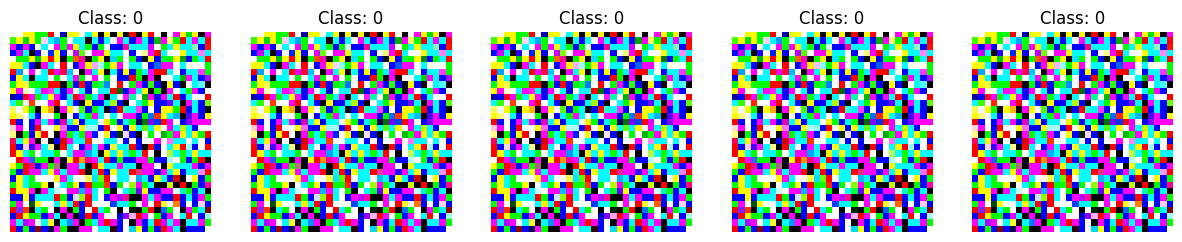

In [11]:
# Save the generator model weights
generator.save_weights('generator_weights.weights.h5')

def generate_images_by_class(generator, class_label):
    """
    Generates and displays 5 images for a specific class label using a Conditional GAN generator.
    """
    # Create random noise and the specific class label for 5 samples
    noise = tf.random.normal([5, 100])
    labels = tf.fill([5, 1], class_label)
    
    # Generate images (assuming generator takes [noise, labels] as input)
    generated_images = generator([noise, labels], training=False)
    
    # Plot the results
    plt.figure(figsize=(15, 3))
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        # Rescale images from [-1, 1] to [0, 1] for visualization
        img = (generated_images[i].numpy() + 1) / 2.0
        if img.shape[-1] == 1:
            plt.imshow(img.squeeze(), cmap='gray')
        else:
            plt.imshow(img)
        plt.title(f"Class: {class_label}")
        plt.axis('off')
    plt.show()

generate_images_by_class(generator, class_label=0)
